# 线性回归

In [10]:
import numpy as np
import matplotlib.pyplot as plt
import copy
import math
%matplotlib inline 

## 问题描述
假设你是一家连锁餐厅的首席执行官，正在考虑在哪些城市开设新店。

- 你希望将业务扩展到可能为餐厅带来更高利润的城市。
- 连锁餐厅已经在多个城市设有门店，你掌握了这些城市的人口和餐厅利润数据。
- 你还掌握了一些候选开店城市的数据。
- 对于这些城市，你已知其人口数量。

你能利用这些数据找出哪些城市可能为业务带来更高的利润吗？

## 3 - 数据集

首先加载本任务所用的数据集。

- 下面的 `load_data()` 函数将数据加载到变量 `x_train` 和 `y_train` 中。
  - `x_train` 表示城市人口。
  - `y_train` 表示该城市餐厅的利润。利润为负值表示亏损。
  - `x_train` 和 `y_train` 都是 NumPy 数组。

In [11]:
# 加载数据集

def load_data():
    data = np.loadtxt('data.txt', delimiter=',')
    x = data[:, 0] # data.txt中每一行的第一列数据，这是一个一维向量
    y = data[:, 1] 
    return x, y

x_train, y_train = load_data()

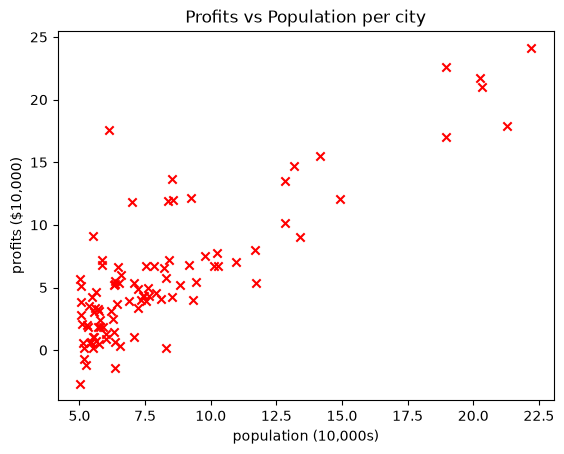

In [12]:
# 可视化数据
plt.scatter(x_train, y_train, marker = 'x', c = 'r')
plt.title('Profits vs Population per city')
plt.ylabel('profits ($10,000)')
plt.xlabel('population (10,000s)')
plt.show()

## 代价函数

$$
J(w,b) = \frac{1}{2m} \sum_{i=1}^{m} (f_{w,b}(x^{(i)}) - y^{(i)})^2
$$

In [13]:
def compute_cost(x, y, w, b):
    """
    计算线性回归的代价函数。

    参数：
    x -- 输入变量，一个 (m, n) 维的 NumPy 数组，其中 m 是样本数量，n 是特征数量。
    y -- 目标变量，一个 (m,) 维的 NumPy 数组，其中 m 是样本数量。
    w, b -- 模型参数

    返回：
        total_cost -- 代价
    """
    m = x.shape[0]

    total_cost = 0

    for i in range(m):
        total_cost += (w * x[i] + b - y[i]) ** 2

    return total_cost / (2 * m)

## 梯度下降

In [14]:
def compute_gradient(x, y, w, b):
    """
    计算线性回归的梯度。

    参数：
    x -- 输入变量，一个 (m, n) 维的 NumPy 数组，其中 m 是样本数量，n 是特征数量。
    y -- 目标变量，一个 (m,) 维的 NumPy 数组，其中 m 是样本数量。

    返回：
        dj_dw -- w 的梯度
        dj_db -- b 的梯度
    """
    m = x.shape[0]

    dj_dw = 0
    dj_db = 0

    for i in range(m):
        tmp = (w * x[i] + b - y[i])
        dj_dw += tmp * x[i]
        dj_db += tmp

    dj_dw /= m
    dj_db /= m

    return dj_dw, dj_db

In [15]:
def gradient_descent(x, y, w_in, b_in, alpha, num_iters, cost_function, gradient_function):
    """
    执行批量梯度下降以学习参数 w 和 b。
    以学习率 alpha 迭代 num_iters 次。

    参数：
    x -- 输入变量，一个 (m, n) 维的 NumPy 数组，其中 m 是样本数量，n 是特征数量。
    y -- 目标变量，一个 (m,) 维的 NumPy 数组，其中 m 是样本数量。
    w_in, b_in -- 初始的参数
    cost_function -- 代价函数
    gradient_function -- 梯度函数
    alpha -- 学习率
    num_iters -- 迭代次数

    返回：
    w, b -- 学习后的参数
    """

    # 用数组保存每次迭代的代价 J 和 W，用于后续绘图
    J_history = []
    w_history = []

    w = copy.deepcopy(w_in) # 避免在函数内修改全局 w
    b = b_in

    for i in range(num_iters):
        # 计算梯度
        dj_dw, dj_db = gradient_function(x, y, w, b)

        # 更新参数
        w = w - alpha * dj_dw
        b = b - alpha * dj_db

        # 计算代价
        if i < 100000:  # 只记录前 100000 次迭代的结果
            cost = cost_function(x, y, w, b)
            J_history.append(cost)

        # 按间隔打印代价，供打印约10次，不足十次则每次都打印
        if i % math.ceil(num_iters / 10) == 0:
            w_history.append(w)
            print(f"Iteration {i}: Cost {cost:.6f} W {w:.6f} b {b:.6f}")

        return w, b, J_history, w_history
    


Iteration 0: Cost 6.737190 W 0.653288 b 0.058391
Final w: 0.653288, b: 0.058391


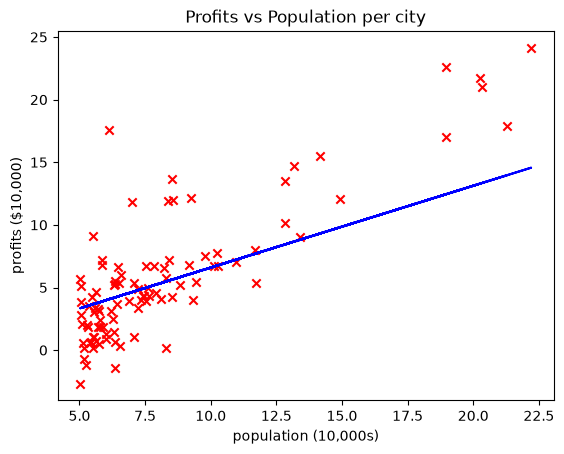

In [16]:
initial_w = 0
initial_b = 0

alpha = 0.01
num_iters = 1000

w, b, J_history, w_history = gradient_descent(x_train, y_train, initial_w, initial_b, alpha, num_iters, compute_cost, compute_gradient)

print(f"Final w: {w:.6f}, b: {b:.6f}")

# 绘制线性拟合结果
m = x_train.shape[0]
preficted = np.zeros(m)

for i in range(m):
    preficted[i] = w * x_train[i] + b

plt.plot(x_train, preficted, c = 'b')
plt.scatter(x_train, y_train, marker = 'x', c = 'r')
plt.title('Profits vs Population per city')
plt.ylabel('profits ($10,000)')
plt.xlabel('population (10,000s)')
plt.show()